# Extract raster values at points

- **`sample(points)`** — read the raster value at each point location (e.g. gauge stations).
- **`extract()`** — pull every valid (non-no-data) cell value into a flat array, handy for
  histograms or training samples.

## Setup

In [1]:
%matplotlib inline

import tempfile
from pathlib import Path

import numpy as np

DATA = Path('../../../examples/data')
WORK = Path(tempfile.mkdtemp(prefix='pyramids-ops-'))
DATA.is_dir(), WORK.is_dir()

(True, True)

In [2]:
from pyramids.dataset import Dataset
from pyramids.feature import FeatureCollection

ds = Dataset.read_file(DATA / 'acc4000.tif')
gauges = FeatureCollection.read_file(DATA / 'coello-gauges.geojson')
ds.shape, ds.epsg, (len(gauges), gauges.epsg)

((1, 13, 14), 32618, (6, 32618))

Plot the raster band we will sample from — the flow-accumulation grid that the gauges sit on.

/home/runner/work/pyramids-core/pyramids-core/.pixi/envs/docs/lib/python3.14/site-packages/matplotlib/colors.py:824: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


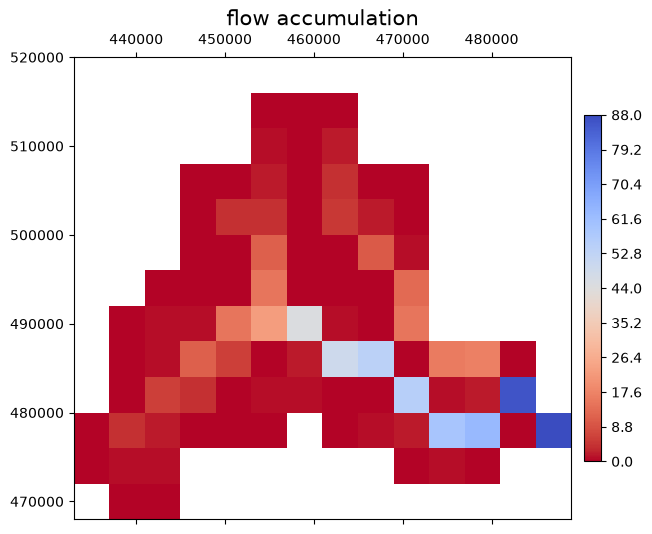

In [3]:
ds.plot(band=0, title='flow accumulation')

## Sample at point locations — `sample`

Returns an array of shape `(bands, n_points)` — one value per band per point.

In [4]:
pts = gauges if gauges.epsg == ds.epsg else FeatureCollection(gauges.to_crs(ds.epsg))
values = ds.sample(pts)
values.shape, np.asarray(values).ravel()

((1, 6), array([ 4.,  6.,  1.,  5., 49., 88.], dtype=float32))

Plot the gauge point locations where the raster was sampled.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

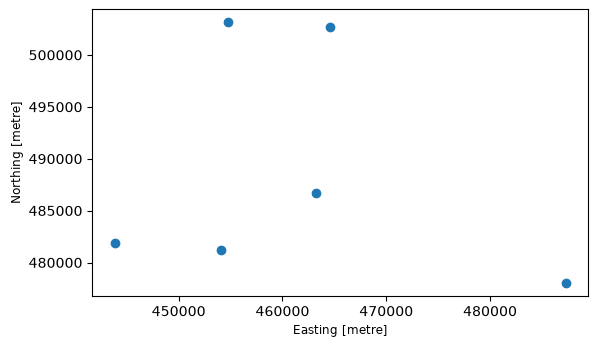

In [5]:
pts.plot()

## All valid cell values — `extract`

A 1-D array of the cells that are not no-data.

In [6]:
cells = ds.extract()
cells.shape, float(cells.min()), float(cells.max())

((89,), 0.0, 88.0)

## Notes

- `sample` accepts a `FeatureCollection`, a GeoDataFrame, or a plain DataFrame of x/y.
- `bands=` on `sample` selects which band(s) to read.
- See also: [Zonal statistics](zonal-statistics.ipynb).